In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from data_setup import RotatedMNIST, create_dataloaders
from model import MultiTaskDNN

Running Data Setup Sanity Check...


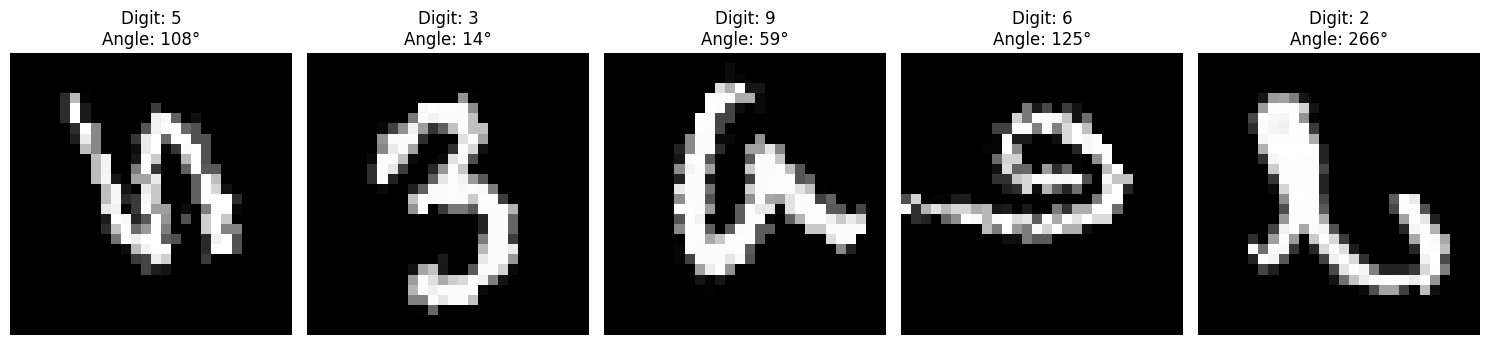

In [2]:
# 1. Create a mock config to test the pipeline locally
mock_data_cfg = {
    'dataset_path': './DNN_Data',
    'batch_size': 32,
    'num_workers': 0,  # Set to 0 to avoid multiprocessing issues during plotting
    'max_digit': 9,
    'max_rotation_degrees': 360
}

print("Running Data Setup Sanity Check...")

# 2. Get the dataloaders
train_loader, _ = create_dataloaders(mock_data_cfg)

# 3. Grab a single batch from the training loader
images, digits, angle_rad, angle_deg = next(iter(train_loader))

# 4. Set up the matplotlib figure
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):
    # Extract the image and remove the channel dimension [1, 28, 28] -> [28, 28]
    img = images[i].squeeze().numpy()

    # Extract values for this particular image
    digit = digits[i].item()
    angle = angle_deg[i].item()

    # Plot the image and set the title
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Digit: {digit}\nAngle: {angle:.0f}°")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [3]:
print("Running Model Architecture Sanity Check...")

mock_model_cfg = {
    'input_shape': 784,
    'shared_layers': 2,
    'task_layers': 2,
    'shared_nodes': 16,
    'task_nodes': 16,
    'digit_out': 10,
    'parity_out': 2,
    'rotation_out': 1
}

mock_train_cfg = {
    'activation': 'relu'
}

# Initialize model
model = MultiTaskDNN(mock_model_cfg, mock_train_cfg)

# Create a dummy batch of 5 images (28x28)
dummy_input = torch.randn(5, 1, 28, 28)

# Pass through the model
digit_preds, oddeven_preds, rot_preds, acts = model(dummy_input)

print(f"Model successfully processed dummy batch of shape {dummy_input.shape}")
print(f"Digit Output Shape: {digit_preds.shape} (Expected: 5, 10)")
print(f"Odd/Even Output Shape: {oddeven_preds.shape} (Expected: 5, 2)")
print(f"Rotation Output Shape: {rot_preds.shape} (Expected: 5, 1)")

print("\nTracked Activations:")
for key, tensor in acts.items():
    print(f"  {key}: shape {tensor.shape}")

Running Model Architecture Sanity Check...
Model successfully processed dummy batch of shape torch.Size([5, 1, 28, 28])
Digit Output Shape: torch.Size([5, 10]) (Expected: 5, 10)
Odd/Even Output Shape: torch.Size([5, 2]) (Expected: 5, 2)
Rotation Output Shape: torch.Size([5, 1]) (Expected: 5, 1)

Tracked Activations:
  Shared_Layer_0: shape torch.Size([5, 16])
  Shared_Layer_1: shape torch.Size([5, 16])
  Digit_Layer_0: shape torch.Size([5, 16])
  Digit_Layer_1: shape torch.Size([5, 16])
  Parity_Layer_0: shape torch.Size([5, 16])
  Parity_Layer_1: shape torch.Size([5, 16])
  Rotation_Layer_0: shape torch.Size([5, 16])
  Rotation_Layer_1: shape torch.Size([5, 16])


In [4]:
# Training configs
training_data_cfg = {
    'dataset_path': './DNN_Data',
    'batch_size': 32,
    'num_workers': 0,  # Set to 0 to avoid multiprocessing issues during plotting
    'max_digit': 9,
    'max_rotation_degrees': 360
}

training_model_cfg = {
    'input_shape': 784,
    'shared_layers': 3,
    'task_layers': 2,
    'shared_nodes': 16,
    'task_nodes': 16,
    'digit_out': 10,
    'parity_out': 2,
    'rotation_out': 1
}

train_cfg = {
    'activation': 'relu'
}

In [81]:
# Full training routine
train_loader, test_loader = create_dataloaders(training_data_cfg)
model = MultiTaskDNN(training_model_cfg, train_cfg)

# Loss functions for each head
digit_loss = nn.CrossEntropyLoss()
parity_loss = nn.CrossEntropyLoss()
angle_loss = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
model.train()
epochs = 50
epoch_losses = []
print("Start of training!")
for epoch in range(epochs):
    # Reset epoch loss
    epoch_loss = 0.0
    
    for images, digits, angle_rad, angle_deg in train_loader:
        # Reset gradients
        optimizer.zero_grad()
        # Determine parity labels
        parity = digits % 2

        # Make predictions
        digit_preds, parity_preds, rot_preds, acts = model(images)

        # Assess loss on each head, then sum together
        l_digit = digit_loss(digit_preds, digits)
        l_parity = parity_loss(parity_preds, parity)
        l_rot = angle_loss(rot_preds, angle_rad)

        full_loss = l_digit + l_parity + l_rot
        
        # Make gradient step backwards
        full_loss.backward()
        optimizer.step()

        # Record losses
        epoch_loss += full_loss.item()

    # At end of each epoch, report avg accuracy
    avg_loss = epoch_loss / len(train_loader)
    print(f"   epoch {epoch+1}: avg batch loss {avg_loss:.4f}"
          f"   (digit {l_digit.item():.4f}, parity {l_parity.item():.4f}, rot {l_rot.item():.4f})")
    epoch_losses.append(avg_loss)

Start of training!


/Users/lyn/miniforge3/envs/allensdk/lib/python3.9/site-packages/torch/nn/modules/loss.py:616: UserWarning: Using a target size (torch.Size([32])) that is different to the input size (torch.Size([32, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


   epoch 1: avg batch loss 10.3207   (digit 1.8129, parity 0.6186, rot 5.7282)
   epoch 2: avg batch loss 5.7978   (digit 1.4442, parity 0.4828, rot 2.8952)
   epoch 3: avg batch loss 5.3041   (digit 1.3892, parity 0.4263, rot 3.6285)
   epoch 4: avg batch loss 5.1801   (digit 1.3366, parity 0.4454, rot 3.6665)
   epoch 5: avg batch loss 5.0696   (digit 1.3378, parity 0.3102, rot 3.9094)
   epoch 6: avg batch loss 5.0162   (digit 1.0495, parity 0.4297, rot 3.4890)
   epoch 7: avg batch loss 4.9677   (digit 1.1566, parity 0.3733, rot 2.8682)
   epoch 8: avg batch loss 4.9389   (digit 1.4136, parity 0.3878, rot 3.6448)
   epoch 9: avg batch loss 4.9064   (digit 1.1404, parity 0.4075, rot 4.0486)
   epoch 10: avg batch loss 4.8570   (digit 0.7167, parity 0.3040, rot 3.4835)
   epoch 11: avg batch loss 4.8273   (digit 1.3158, parity 0.3550, rot 2.9869)
   epoch 12: avg batch loss 4.7966   (digit 1.3265, parity 0.4463, rot 3.1144)
   epoch 13: avg batch loss 4.7720   (digit 1.2492, parity 0

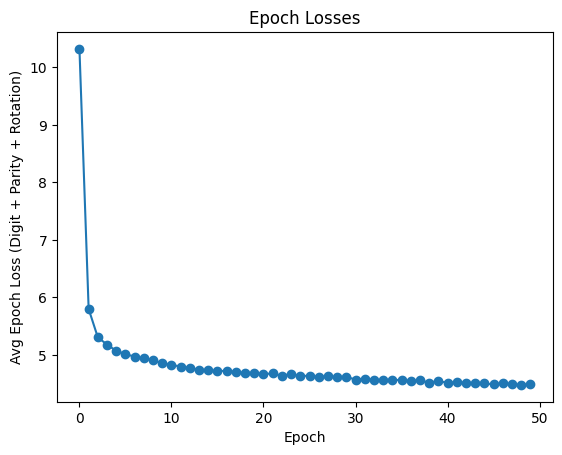

In [82]:
plt.plot(range(epochs), epoch_losses, '-o')
plt.title("Epoch Losses")
plt.xlabel("Epoch")
plt.ylabel("Avg Epoch Loss (Digit + Parity + Rotation)")
plt.show()

In [91]:
torch.save(model.state_dict(), '50-epoch-model.pkl')

In [92]:
test_model = MultiTaskDNN(training_model_cfg, train_cfg)
test_model.load_state_dict(torch.load('50-epoch-model.pkl'))

<All keys matched successfully>

In [ ]:
for images, digits, angle_rad, angle_deg in train_loader:
    # Determine parity labels
    parity = digits % 2

    # Make predictions
    digit_preds, parity_preds, rot_preds, acts = model(images)

    break

In [30]:
# Evaluate model on held-out test data
total_digit_loss, total_parity_loss, total_rot_loss = 0.0, 0.0, 0.0
total_batches = 0
model.eval()
for images, digits, angle_rad, angle_deg in train_loader:
    # Determine parity labels
    parity = digits % 2

    # Make predictions
    digit_preds, parity_preds, rot_preds, acts = model(images)

    # Accumulate losses
    total_digit_loss += digit_loss(digit_preds, digits).item()
    total_parity_loss += parity_loss(parity_preds, parity).item()
    total_rot_loss += angle_loss(rot_preds, angle_rad).item()
    
    total_batches += 1

avg_total_loss = (total_digit_loss + total_parity_loss + total_rot_loss) / total_batches
avg_digit_loss = total_digit_loss / total_batches
avg_parity_loss = total_parity_loss / total_batches
avg_rot_loss = total_rot_loss / total_batches
print(f"avg test batch loss {avg_total_loss:.4f}"
      f"   (digit {avg_total_loss:.4f}, parity {avg_parity_loss:.4f}, rot {avg_rot_loss:.4f})")

avg test batch loss 4.6182   (digit 4.6182, parity 0.3252, rot 3.3189)


In [63]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
rot_preds, rot_labels = [], []

with torch.no_grad():
    for images, digits, angle_rad, angle_deg in train_loader:
        _, _, rot_pred, _ = model(images)
        rot_preds.append(rot_pred.cpu())
        rot_labels.append(angle_rad.cpu())

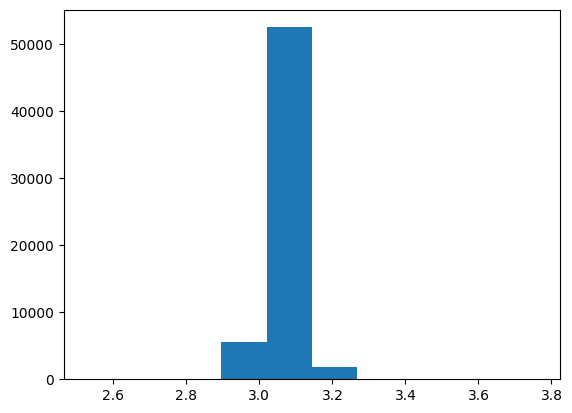

In [80]:
plt.hist(rot_preds_arr)
plt.show()

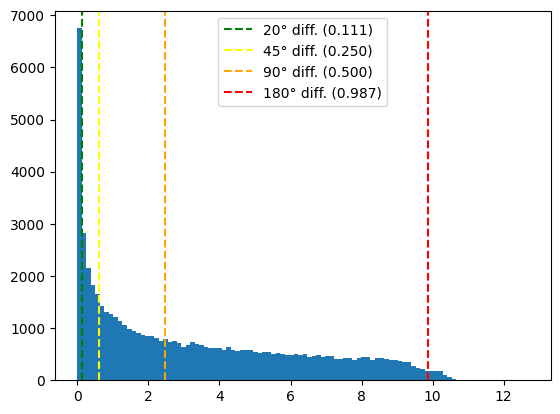

In [71]:
# Rotation plot
rot_preds_arr  = torch.cat(rot_preds).numpy().flatten()
rot_labels_arr = torch.cat(rot_labels).numpy()

rot_mse_losses = (rot_preds_arr - rot_labels_arr) ** 2
diff = rot_preds_arr - rot_labels_arr
circular_err_rad = np.abs(np.arctan2(np.sin(diff), np.cos(diff)))

plt.hist(rot_mse_losses, bins=100)
# Thresholds are in degrees; MSE is in rad^2, so square the radian threshold
for deg, color in [(20, "green"), (45, "yellow"), (90, "orange"), (180, "red")]:
    thresh_rad2 = np.deg2rad(deg) ** 2
    thresh_mean = (rot_mse_losses < thresh_rad2).mean()
    plt.axvline(thresh_rad2, color=color, linestyle="--", label=f"{deg}° diff. ({thresh_mean:.03f})")

plt.legend()
plt.show()

In [ ]:
# Digit Plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
disp.plot(cmap="Blues", values_format="d")
plt.title("Radian Rotation Confusion Matrix")
plt.show()

In [42]:
overall_acc = cm.trace() / cm.sum()
print(f"Overall accuracy: {overall_acc:.4f}")

Overall accuracy: 0.6829
